# Assignments: Cleaning Data

## 1. Data in Python Request

* Read in data from the Excel spreadsheet (Alarm Survey Data.xlsx) and put into a Pandas DataFrame
* Check the data type of each column
* Convert object columns into numeric or datetime columns, as needed

In [4]:
from math import isnan

import pandas as pd
import numpy as np
from pandas import read_excel

In [10]:
happiness = pd.read_csv("../Data/happiness_survey_data.csv")

In [13]:
happiness

,country_name,year,happiness_score,social_support,freedom_to_make_life_choices,healthy_life_expectancy_at_birth
0,Afghanistan,2008,3.723590,0.450662,0.718114,50.500000
1,Afghanistan,2009,4.401778,0.552308,0.678896,50.799999
2,Afghanistan,2010,4.758381,0.539075,0.600127,51.099998
3,Afghanistan,2011,3.831719,0.521104,0.495901,51.400002
4,Afghanistan,2012,3.782938,0.520637,0.530935,51.700001
...,...,...,...,...,...,...
2084,Zimbabwe,2017,3.638300,0.754147,0.752826,52.150002
2085,Zimbabwe,2018,3.616480,0.775388,0.762675,52.625000
2086,Zimbabwe,2019,2.693523,0.759162,0.631908,53.099998
2087,Zimbabwe,2020,3.159802,0.717243,0.643303,53.575001


## 2. Missing Data Check

* Find any missing data
* Deal with the missing data

In [16]:
happiness.info()

<class 'pandas.DataFrame'>
RangeIndex: 2089 entries, 0 to 2088
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   country_name                      2089 non-null   str    
 1   year                              2089 non-null   int64  
 2   happiness_score                   2089 non-null   float64
 3   social_support                    2076 non-null   float64
 4   freedom_to_make_life_choices      2057 non-null   float64
 5   healthy_life_expectancy_at_birth  2031 non-null   float64
dtypes: float64(4), int64(1), str(1)
memory usage: 98.1 KB


In [31]:

happiness[happiness["freedom_to_make_life_choices"].isna() == True]

,country_name,year,happiness_score,social_support,freedom_to_make_life_choices,healthy_life_expectancy_at_birth
30,Algeria,2014,6.354898,0.818189,NaN,65.900002
31,Algeria,2016,5.340854,0.748588,NaN,66.099998
120,Bahrain,2014,6.165134,NaN,NaN,65.959999
278,Cambodia,2006,3.568745,0.793081,NaN,57.639999
361,China,2006,4.560495,0.747011,NaN,65.660004
362,China,2007,4.862862,0.810852,NaN,65.919998
369,China,2014,5.195619,0.820366,NaN,67.739998
370,China,2015,5.303878,0.793734,NaN,68.000000
371,China,2016,5.324956,0.741703,NaN,68.125000
531,Egypt,2008,4.631741,0.738364,NaN,61.580002


In [27]:
happiness

,country_name,year,happiness_score,social_support,freedom_to_make_life_choices,healthy_life_expectancy_at_birth
0,Afghanistan,2008,3.723590,0.450662,0.718114,50.500000
1,Afghanistan,2009,4.401778,0.552308,0.678896,50.799999
2,Afghanistan,2010,4.758381,0.539075,0.600127,51.099998
3,Afghanistan,2011,3.831719,0.521104,0.495901,51.400002
4,Afghanistan,2012,3.782938,0.520637,0.530935,51.700001
...,...,...,...,...,...,...
2084,Zimbabwe,2017,3.638300,0.754147,0.752826,52.150002
2085,Zimbabwe,2018,3.616480,0.775388,0.762675,52.625000
2086,Zimbabwe,2019,2.693523,0.759162,0.631908,53.099998
2087,Zimbabwe,2020,3.159802,0.717243,0.643303,53.575001


## 3. Inconsistent Text & Typos Check

* Find any inconsistent text and typos
* Deal with the inconsistent text and typos

In [33]:
df = pd.read_excel("../Data/Alarm Survey Data.xlsx")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   survey_id           6433 non-null   int64  
 1   age                 6433 non-null   int64  
 2   number_of_children  6433 non-null   float64
 3   activity_level      6433 non-null   str    
 4   sleep_quality       6082 non-null   float64
 5   number_of_snoozes   6433 non-null   int64  
 6   alarm_rating        6433 non-null   str    
dtypes: float64(2), int64(3), str(2)
memory usage: 351.9 KB


In [34]:
df.describe()

,survey_id,age,number_of_children,sleep_quality,number_of_snoozes
count,6433.000000,6433.000000,6433.000000,6082.000000,6433.000000
mean,3216.302192,29.069175,1.395616,4.232654,1.145811
std,1856.007409,7.472048,1.432192,0.842448,1.599481
min,1.000000,13.000000,0.000000,1.000000,0.000000
25%,1609.000000,23.000000,0.000000,4.000000,0.000000
50%,3217.000000,28.000000,1.000000,4.000000,0.000000
75%,4825.000000,34.000000,2.000000,5.000000,2.000000
max,6366.000000,47.000000,5.500000,5.000000,19.000000


In [35]:
df.number_of_children.value_counts()

number_of_children
0.0    2440
2.0    1498
1.0    1172
3.0     788
4.0     331
5.5     204
Name: count, dtype: int64

In [16]:
df.activity_level = df.activity_level.map({
    "light_activity":"light_activity",
    "lightly active":"light_activity",
    "light": "light_activity",
    "very active":"very active",
    "active":"active"
});
df.activity_level.value_counts()

activity_level
light_activity    3314
active            2450
very active        669
Name: count, dtype: int64

In [38]:
df[df.duplicated(keep=False)]

,survey_id,age,number_of_children,activity_level,sleep_quality,number_of_snoozes,alarm_rating
6299,6300,31,2.0,active,5.0,0,3 stars
6300,6301,27,2.0,lightly active,4.0,0,2 stars
6301,6302,41,3.0,lightly active,5.0,0,2 stars
6302,6303,25,0.0,lightly active,5.0,0,5 stars
6303,6304,25,1.0,lightly active,5.0,0,2 stars
...,...,...,...,...,...,...,...
6428,6362,27,2.0,active,5.0,0,5 stars
6429,6363,31,1.0,light,4.0,0,4 stars
6430,6364,26,0.0,lightly active,5.0,0,3 stars
6431,6365,27,1.0,active,5.0,0,3 stars


In [32]:
df.drop_duplicates(inplace=True)
df

,survey_id,age,number_of_children,activity_level,sleep_quality,number_of_snoozes,alarm_rating
0,1,34,3.0,active,3.0,1,5 stars
1,2,31,3.0,light_activity,3.0,3,3 stars
2,3,18,0.0,light_activity,4.0,1,1 stars
3,4,42,4.0,active,4.0,1,4 stars
4,5,30,1.0,light_activity,1.0,4,3 stars
...,...,...,...,...,...,...,...
6361,6362,27,2.0,active,5.0,0,5 stars
6362,6363,31,1.0,light_activity,4.0,0,4 stars
6363,6364,26,0.0,light_activity,5.0,0,3 stars
6364,6365,27,1.0,active,5.0,0,3 stars


## 4. Duplicate Data Check

* Find any duplicate data
* Deal with the duplicate data

## 5. Outliers Check

* Find any outliers
* Deal with the outliers

In [109]:
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_excel("../Data/Student Grades.xlsx")

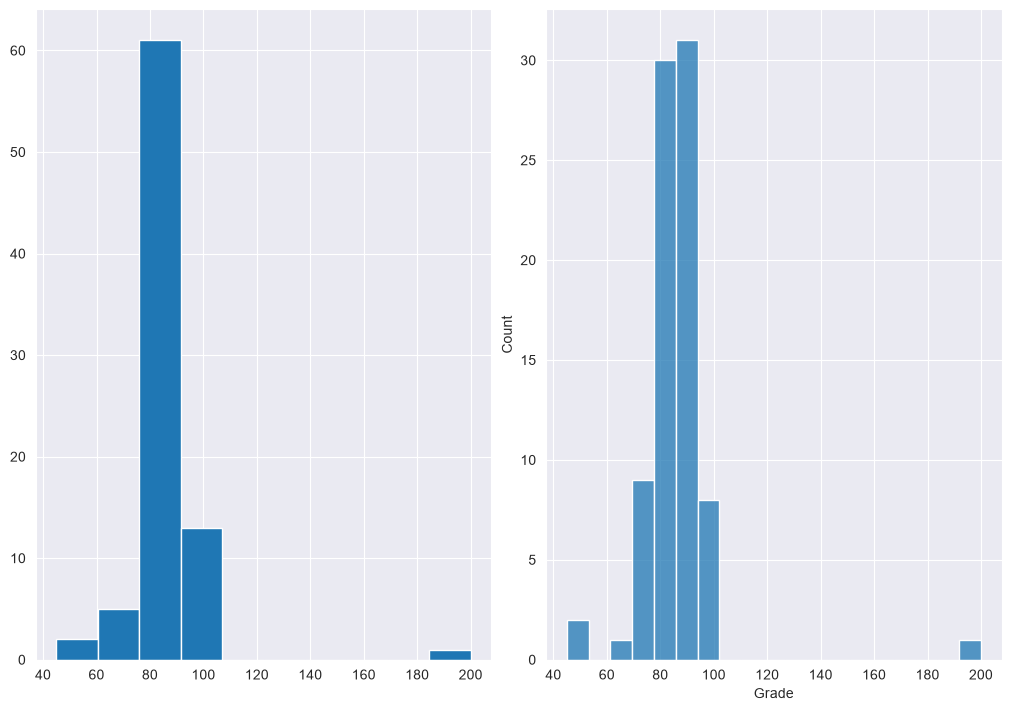

In [110]:
fig, axs = plt.subplots(1,2, figsize=(10,7), layout="constrained")

axs[0].hist(df['Grade'])
axs[1] = sns.histplot(df['Grade'])

In [111]:
# df.hist(bins=10)
# df.Grade.max() - df.Grade.mean()
# sns.histplot(df,bins=10)
# sns.boxplot(x=df['Grade'])
# df.Grade = df.Grade.where(df.Grade<=100,100)
mean = np.mean(df.Grade)
sd = np.std(df.Grade)
[grade for grade in df['Grade'] if (grade < mean - 3 * sd) or (grade > mean + 3 * sd)]

[200.0]

In [108]:
# q25,q50,q75 = np.nanpercentile(df.Grade,[25,50,75])
# iqr = q75 - q25
# print(iqr)
# min_grade = q25 - 1.5*iqr
# max_grade = q75 + 1.5*iqr
# print(q25,q50,q75)
# print(min_grade,max_grade)
df.min()

Student       Aaron
Class           EDA
Year       Freshman
Grade          45.0
dtype: object

## 6. Data Issues Check

* Quickly explore the updated DataFrame. How do things look now after handling the data issues compared to the original DataFrame?

## 7. Create Columns From Numeric Data

* Read data into Python
* Check the data type of each column
* Create a numeric column using arithmetic
* Create a numeric column using conditional logic

In [ ]:
# Create a “Total Spend” column that includes both the pen cost and shipping cost for each sale
# Create a “Free Shipping” column that says yes if the sale included free shipping, and no otherwise

## 8. Create Columns From DateTime Data

* Calculate the difference between two datetime columns and save it as a new column
* Take the average of a column

In [ ]:
# Calculate the number of days between the purchase and delivery date for each sale
# Save it as a new column called “Delivery Time”
# What were the average days from purchase to delivery?

## 9. Create Columns From Text Data

* Split one column into multiple columns
* Create a Boolean column (True / False) to show whether a text field contains particular words

In [ ]:
# Split the reviews on the “|” character to create two new columns: “User Name” and “Review Text”
# Create a “Leak or Spill” column that flags the reviews that mention either “leak” or “spill”